<a href="https://colab.research.google.com/github/palakmirok/radar-detection-performance/blob/main/CA_vs_OS_CFAR_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

CA-CFAR detections: [106]
OS-CFAR detections: [100, 106, 151]


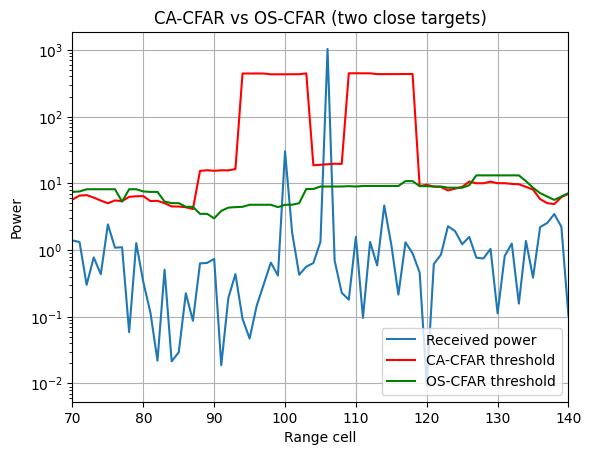

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

np.random.seed(1)
N = 200
x = (np.random.randn(N) + 1j*np.random.randn(N)) / np.sqrt(2)


for pos, snr_db in [(100, 15), (106, 30)]:
    x[pos] += np.sqrt(10**(snr_db/10))
power = np.abs(x)**2

train, guard, pfa = 10, 2, 1e-3
n = 2*train
k = int(0.75*n)                              # OS-CFAR rank

alpha_ca = n * (pfa**(-1/n) - 1)

def f(T):
    i = np.arange(n-k+1, n+1)
    return np.prod(i/(i+T)) - pfa
alpha_os = brentq(f, 0.1, 1000)

th_ca = np.full(N, np.nan)
th_os = np.full(N, np.nan)
det_ca, det_os = [], []

for i in range(train+guard, N-train-guard):
    left  = power[i-guard-train : i-guard]
    right = power[i+guard+1 : i+guard+train+1]
    cells = np.concatenate([left, right])

    th_ca[i] = alpha_ca * cells.mean()
    th_os[i] = alpha_os * np.sort(cells)[k-1]

    if power[i] > th_ca[i]: det_ca.append(i)
    if power[i] > th_os[i]: det_os.append(i)

print("CA-CFAR detections:", det_ca)
print("OS-CFAR detections:", det_os)

plt.semilogy(power, label='Received power')
plt.semilogy(th_ca, 'r', label='CA-CFAR threshold')
plt.semilogy(th_os, 'g', label='OS-CFAR threshold')
plt.xlim(70, 140)
plt.xlabel('Range cell'); plt.ylabel('Power')
plt.title('CA-CFAR vs OS-CFAR (two close targets)')
plt.legend(); plt.grid(True); plt.show()